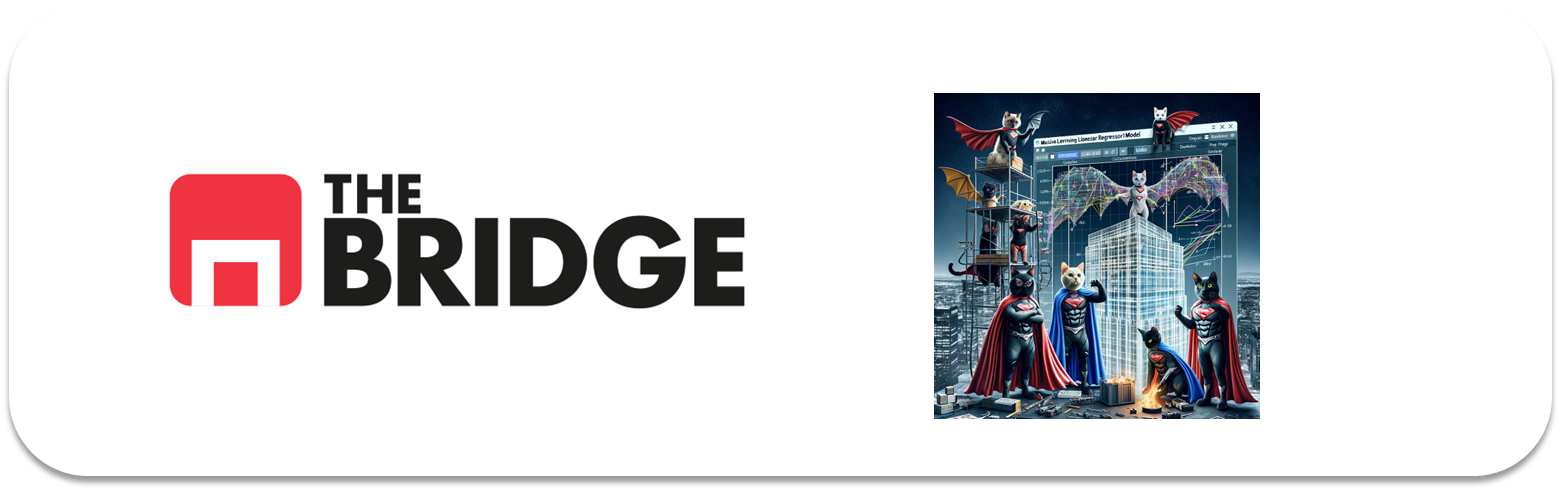

## Clasificación Multicategórica con Regresión Logística

### Entender el problema

Para mostrar la creación de un modelo multiclase y su evaluación vamos a tratar un problema en el que queremos detectar cuál es el sistema operativo de los usuarios que acceden a una dirección web específica (y que no es importante para el problema) en la que pasan un tiempo determinado, navegan a través de las páginas del site, realizan un conjunto de acciones y dejan una valoración de la misma. Encontrarás una variable "clase" que contiene el target, esta vez no tendrás que buscarlo, y que toma tres posibles valores en función del OS: Windows, Linux, Mac. 

Creemos ese modelo predictor a partir de una regresión logística.

### Preparación Datos: Primer vistazo

In [10]:
import pandas as pd
import numpy as np
from sklearn import linear_model
from sklearn import model_selection
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

In [11]:
df_os = pd.read_csv("../data/usuarios_win_mac_lin.csv")

clases = {
    0: 'Windows',
    1: 'Linux',
    2: 'Mac'
}

df_os.head()

,duracion,paginas,acciones,valor,clase
0,7.0,2,4,8,2
1,21.0,2,6,6,2
2,57.0,2,4,4,2
3,101.0,3,6,12,2
4,109.0,2,6,12,2


In [12]:
df_os.info()

<class 'pandas.DataFrame'>
RangeIndex: 170 entries, 0 to 169
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   duracion  170 non-null    float64
 1   paginas   170 non-null    int64  
 2   acciones  170 non-null    int64  
 3   valor     170 non-null    int64  
 4   clase     170 non-null    int64  
dtypes: float64(1), int64(4)
memory usage: 6.8 KB


Mostramos el target, y su balanceo o desbalanceo normalizado

In [13]:
df_os.clase.value_counts(True)

clase
0    0.505882
2    0.258824
1    0.235294
Name: proportion, dtype: float64

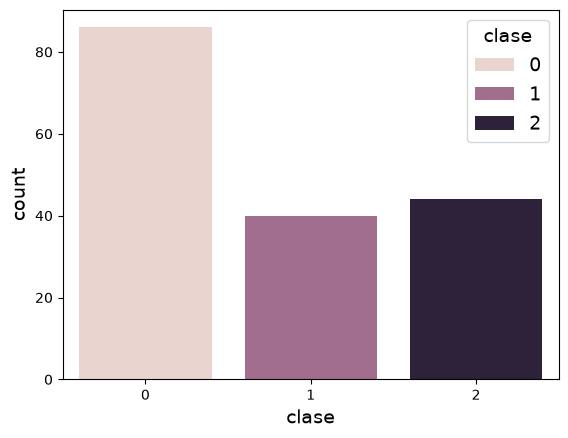

In [14]:
sns.countplot(x = "clase", data = df_os, hue = "clase");

Windows es el sistema dominante (la mitad de los usuarios): habrá que tenerlo en cuenta al elegir las métricas y, aunque aquí no lo haremos, también al modelar (lo veremos en sesiones posteriores).

Echamos un vistazo, y solo eso, a la distribución de las variables continuas (o sea casi todas) y nos fijamos en escala y figura

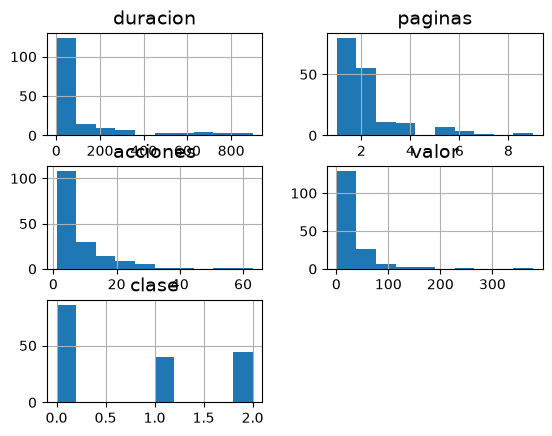

In [15]:
df_os.hist();

Tiene pinta de que vamos a tener que escalar y hacer alguna transformación para "normalizar" las distribuciones.

### Split

Son muy pocos datos (170) pero vamos a hacer el split igual para que vayamos cogiendo el hábito. Además estratificamos sobre el target (pero ojo esto es para hacer más limpio el ejercicio, por ejemplo porque suponemos que es algo que se va a mantener debido al marketshare de cada sistema operativo)

In [16]:
train_set, test_set = train_test_split(df_os, test_size= 0.2, stratify= df_os["clase"], random_state= 42)

In [17]:
train_set["clase"].value_counts(normalize = True)

clase
0    0.507353
2    0.257353
1    0.235294
Name: proportion, dtype: float64

In [18]:
test_set["clase"].value_counts(normalize = True)

clase
0    0.500000
2    0.264706
1    0.235294
Name: proportion, dtype: float64

No es perfecto, pero prueba a hacer el split sin estratificar.

### Mini-EDA

Vamos a ver la distribución de las features y su relación con el target (con un target multiclase nominal la correlación lineal no tiene sentido), aunque son tan pocas que no vamos a quitar ninguna:

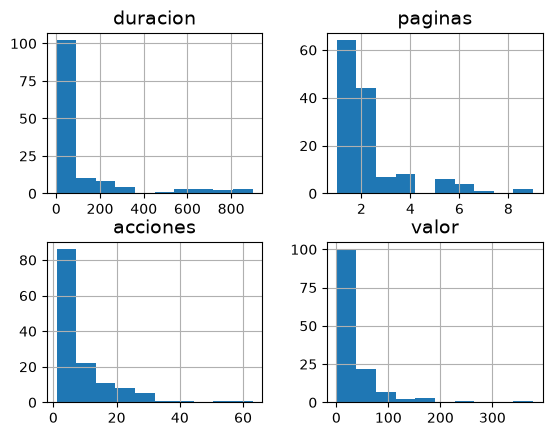

In [19]:
train_set.drop("clase", axis = 1).hist()
plt.show()

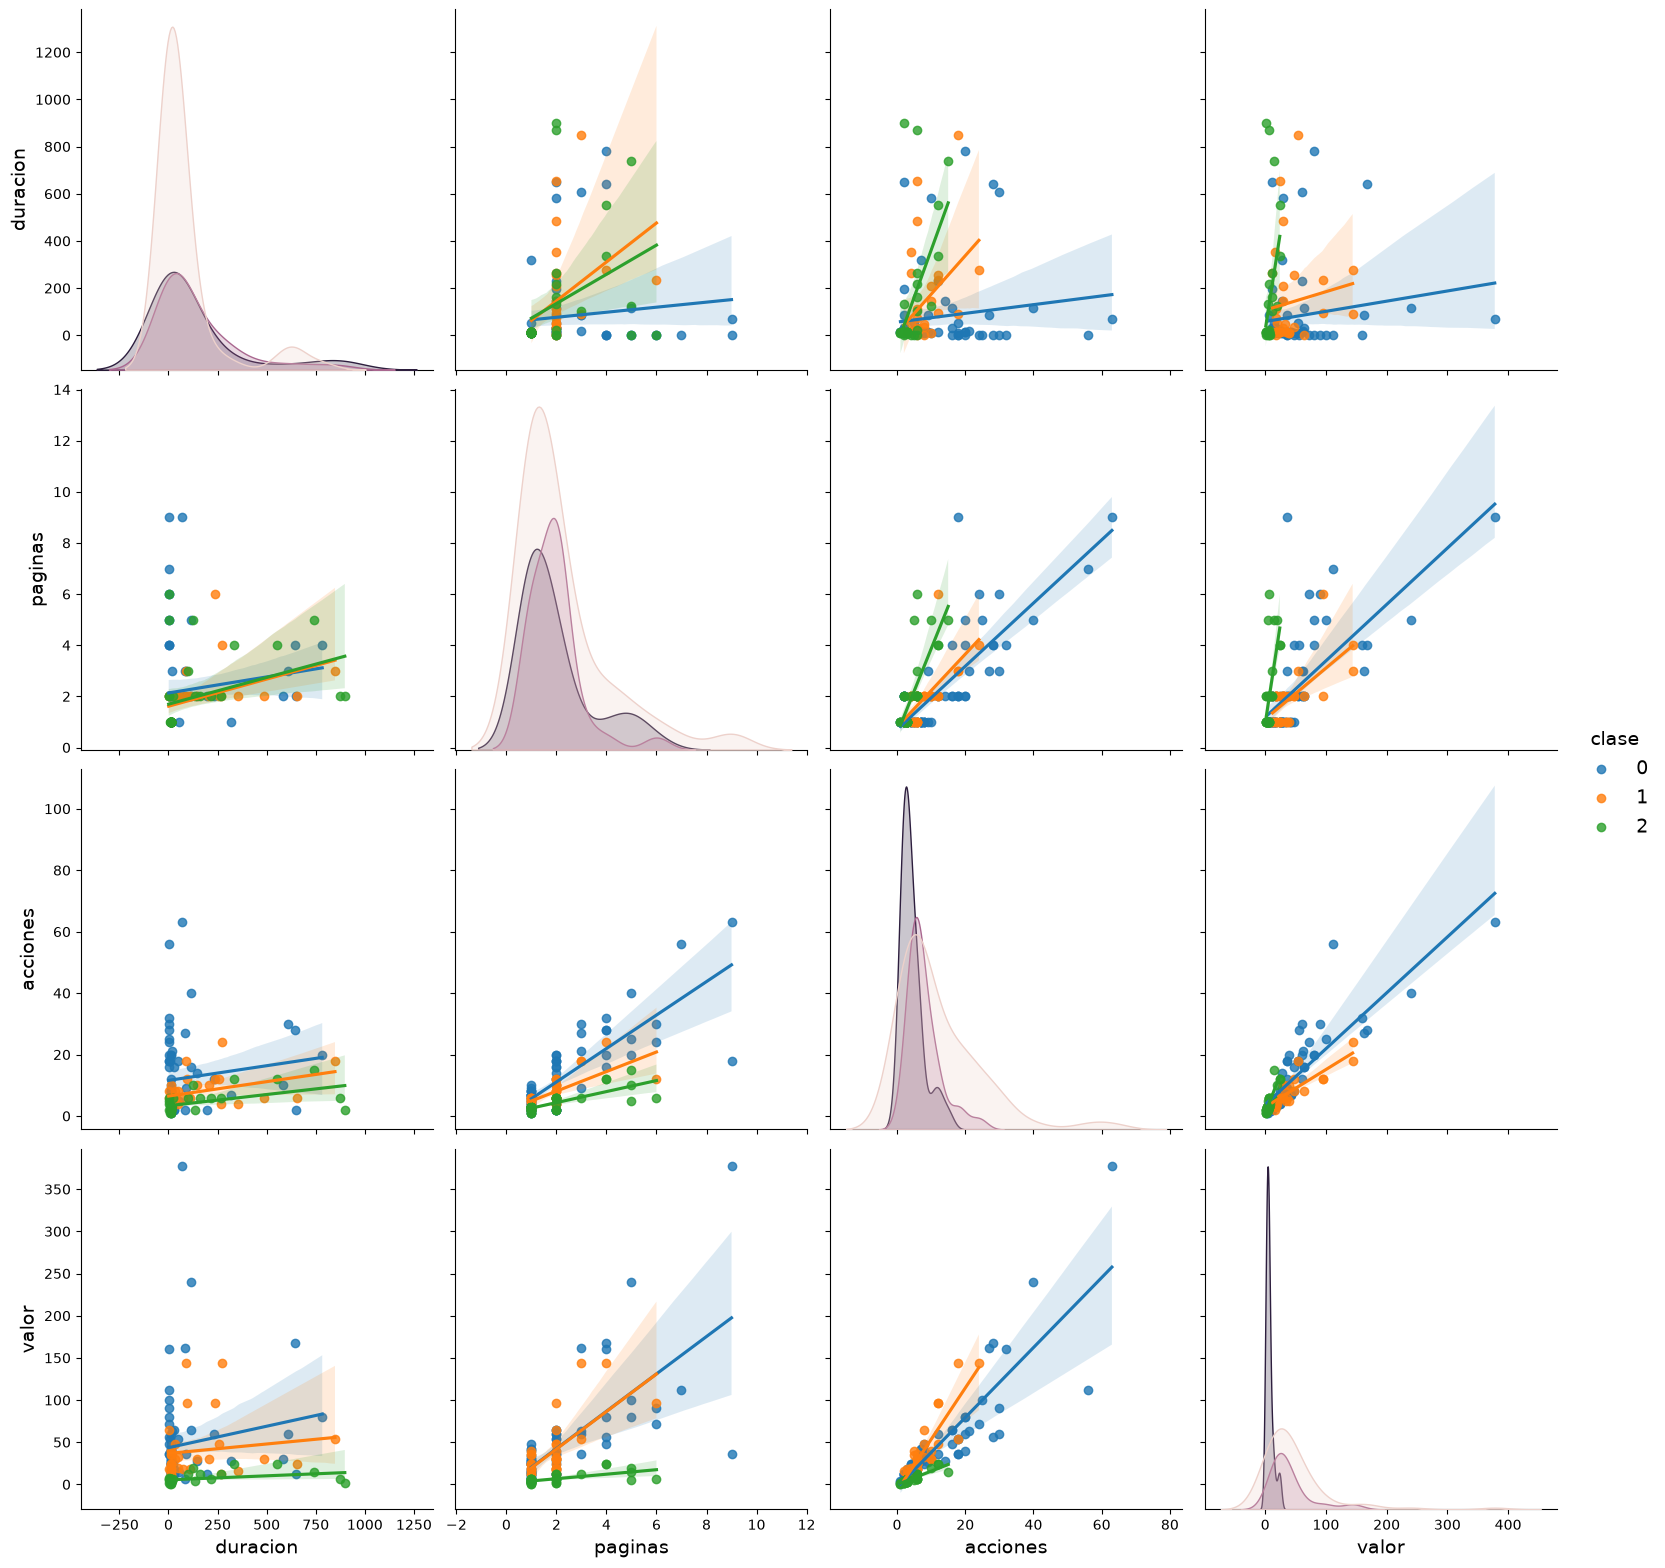

In [20]:
sns.pairplot(train_set,
            hue='clase',
            height=4,
            vars=["duracion", "paginas","acciones","valor"],
            kind='reg'); # "reg" de regresión lineal

In [21]:
features = train_set.drop("clase", axis = 1).columns.to_list()
print(features)

['duracion', 'paginas', 'acciones', 'valor']


### Procesamiento de Features

array([[<Axes: title={'center': 'duracion'}>,
        <Axes: title={'center': 'paginas'}>],
       [<Axes: title={'center': 'acciones'}>,
        <Axes: title={'center': 'valor'}>]], dtype=object)

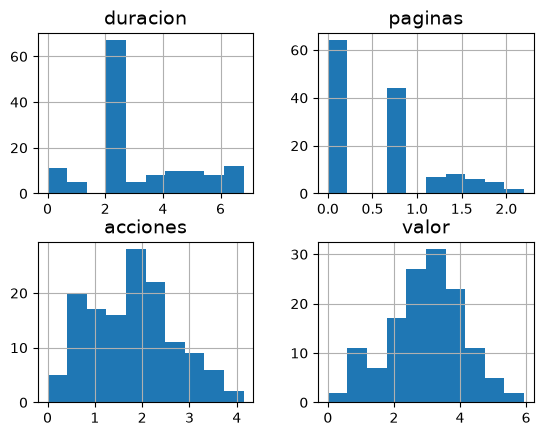

In [22]:
for col in features:
    train_set[col] = train_set[col].apply(np.log)
train_set[features].hist()

In [23]:
for col in features:
    test_set[col] = test_set[col].apply(np.log)
# Ojo ni lo mires :-), pero tienes que aplicarle las mismas transformaciones que el train.

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(train_set[features]) # Adaptamos el StandardScaler al Train, pero luego usamos el mismo en el test (porque ya la media y la desviación son las del train)
X_train = pd.DataFrame(scaler.transform(train_set[features]), columns = features)
X_test = pd.DataFrame(scaler.transform(test_set[features]), columns= features)
X_train.describe()

,duracion,paginas,acciones,valor
count,1.360000e+02,1.360000e+02,1.360000e+02,1.360000e+02
mean,-1.632681e-16,-4.571507e-17,2.416368e-16,-3.395976e-16
std,1.003697e+00,1.003697e+00,1.003697e+00,1.003697e+00
min,-1.878357e+00,-8.947527e-01,-2.004312e+00,-2.501146e+00
25%,-4.781410e-01,-8.947527e-01,-7.831545e-01,-7.258228e-01
50%,-3.805922e-01,2.695613e-01,-1.268982e-02,2.121177e-01
75%,7.491348e-01,2.695613e-01,7.577748e-01,6.482352e-01
max,2.092503e+00,2.796035e+00,2.600971e+00,2.565771e+00


In [25]:
y_train = train_set["clase"]
y_test = test_set["clase"]

### Creamos el modelo

In [26]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression(max_iter=10000) 

clf.fit(X_train, y_train) # No hay que decir nada en especial: detecta que hay más de dos clases y entrena un modelo multinomial (softmax)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

Si mostramos los coeficientes o pesos del modelo veremos una fila por clase: el modelo calcula una "puntuación" lineal para cada clase y las convierte en probabilidades (que suman 1) con la función **softmax**. Es la regresión logística **multinomial**, la que usa sklearn por defecto en problemas multiclase.

Ojo, no es un one-vs-rest (entrenar un modelo binario independiente por clase, la otra estrategia que vimos en teoría): fíjate en que, para cada feature, los coeficientes de las tres clases suman 0. Eso solo ocurre porque los tres se ajustan a la vez.

In [ ]:
# Cómo leer los coeficientes: Lo que importa es comparar filas dentro de una misma columna (P0,P1 y P2)
# por ej: Si la feature 4 sube, z₂ baja mucho y z₁ sube más que z₀. Un valor alto de esa variable empuja hacia la clase 1 y aleja de la clase 2. Un valor bajo hace lo contrario. Es la variable más discriminante de las cuatro, por la magnitud de sus pesos.
clf.coef_

array([[-0.33863361, -0.28274505, -0.12062857,  1.06620115],
       [ 0.20874616, -0.29908782, -0.96460776,  1.88037632],
       [ 0.12988745,  0.58183287,  1.08523633, -2.94657748]])

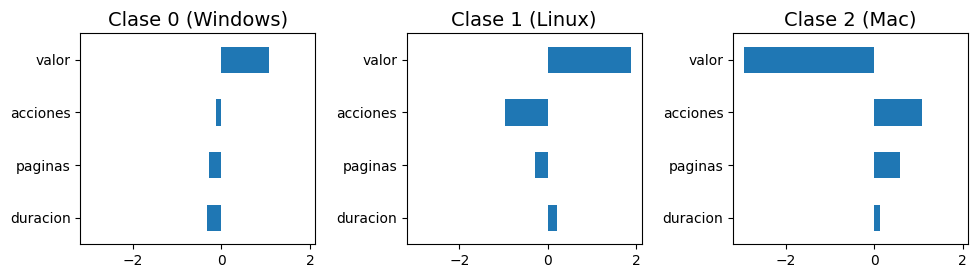

In [19]:
df_coefs = pd.DataFrame(clf.coef_, columns=X_train.columns)

fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharex=True)
for i, subdf in df_coefs.iterrows():
    subdf.plot(kind="barh", ax=ax[i])
    ax[i].set_title(f"Clase {i} ({clases[i]})")

fig.tight_layout()

Ten en cuenta que estos coeficientes están aplicados sobre el logaritmo de las variables, aún así puedes ver que influye en la selección de cada clase.

Tras escalar, cada feature tiene media 0 y desviación estándar 1, así que una unidad de la feature equivale a una desviación estándar.
Cada coeficiente w es cuánto cambia la puntuación z de esa clase cuando la feature sube 1 unidad y las demás se quedan quietas.

Podemos ver las predicciones

In [20]:
clf.predict(X_train)

array([0, 2, 0, 0, 2, 2, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
       2, 2, 0, 1, 0, 0, 0, 2, 1, 0, 0, 0, 2, 0, 2, 0, 2, 0, 0, 0, 0, 2,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 1,
       0, 2, 2, 0, 0, 2, 0, 2, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 2, 2, 2, 0,
       0, 0, 0, 0, 0, 2, 2, 2, 2, 0, 0, 2, 0, 0, 0, 2, 0, 2, 0, 2, 0, 1,
       0, 0, 1, 1, 0, 2, 0, 0, 0, 0, 0, 2, 0, 1, 2, 0, 2, 0, 2, 2, 0, 2,
       2, 0, 2, 0], dtype=int64)

Y las probabilidades para cada instancia, nos da un vector de tres probabilidades una para cada clase y puedes comprobar que escoge la de mayor probabilidad:

In [ ]:
# Cada fila, (P1,P2 y P0) debería de dar 1
clf.predict_proba(X_train)

array([[0.71644988, 0.2743894 , 0.00916072],
       [0.39525661, 0.10499886, 0.49974453],
       [0.62553767, 0.33527652, 0.03918582],
       [0.67466005, 0.32187826, 0.00346169],
       [0.19053689, 0.13965596, 0.66980715],
       [0.38941522, 0.10636455, 0.50422023],
       [0.53907471, 0.45969679, 0.00122851],
       [0.75884966, 0.2158255 , 0.02532484],
       [0.46966258, 0.05475959, 0.47557783],
       [0.59096562, 0.24208018, 0.16695421],
       [0.68823716, 0.30915273, 0.00261011],
       [0.70714319, 0.28772779, 0.00512902],
       [0.74887583, 0.21917341, 0.03195076],
       [0.71324451, 0.26650969, 0.02024579],
       [0.80850583, 0.17530331, 0.01619086],
       [0.70440058, 0.21908523, 0.07651419],
       [0.60969579, 0.38175854, 0.00854567],
       [0.57631578, 0.38246988, 0.04121434],
       [0.8860096 , 0.06851385, 0.04547655],
       [0.59458687, 0.3295515 , 0.07586163],
       [0.48135544, 0.49433957, 0.02430499],
       [0.33808028, 0.52313293, 0.13878679],
       [0.

In [22]:
from sklearn.metrics import accuracy_score

acc_train = accuracy_score(y_train, clf.predict(X_train))
print(acc_train)

0.7279411764705882


En este caso vemos que el accuracy es superior a la proporción de la clase mayoritaria (51%), no tiene mala pinta (pero recuerda que es el train). No vamos a ver el test, antes vamos a usar la validación cruzada y luego veremos las métricas para multiclase.

***

### Validamos el modelo

Usemos la validación cruzada no tanto para comparar con otros modelos, que no tenemos, sino como para adelantarnos a la evaluación con el test y de nuevo ir cogiendo hábito.

In [23]:
from sklearn import model_selection
name='Logistic Regression'
cv_results = model_selection.cross_val_score(clf, X_train, y_train, cv=5, scoring='accuracy')

msg = "%s: %f (%f)" % (name, cv_results.mean(), cv_results.std())
print(cv_results)
print(msg)

[0.64285714 0.62962963 0.66666667 0.66666667 0.77777778]
Logistic Regression: 0.676720 (0.052496)


Ya vemos que sale menor que el 72% del train. 

### Evaluación del modelo

In [24]:
from sklearn.metrics import precision_score, recall_score, accuracy_score, balanced_accuracy_score,\
                            roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay

In [25]:
y_proba = clf.predict_proba(X_test)
y_pred = clf.predict(X_test)

#### Matriz de confusion

A mano, como un dataframe a partir de los datos que nos da el `confusion_matrix` de sklearn:

In [26]:
cm = pd.DataFrame(confusion_matrix(y_test, y_pred), index=[f"Real {i}" for i in clf.classes_], 
                  columns=[f"Predicho {i}" for i in clf.classes_])

cm

,Predicho 0,Predicho 1,Predicho 2
Real 0,14,0,3
Real 1,3,5,0
Real 2,0,0,9


Gráficamente:

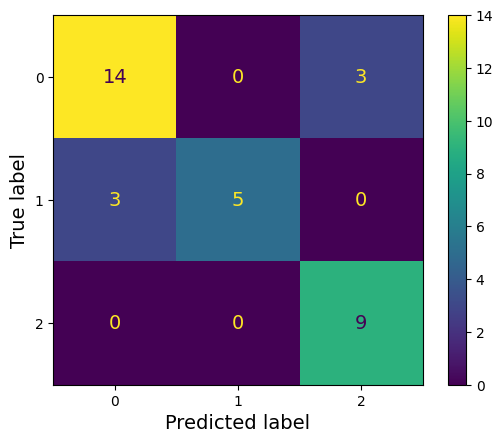

In [27]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

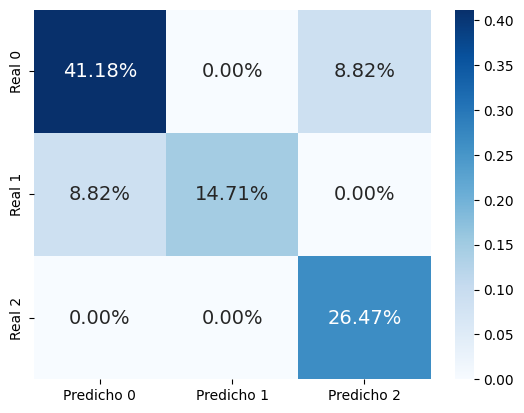

In [28]:
sns.heatmap(cm / cm.values.sum(), annot=True, 
            fmt='.2%', cmap='Blues');

### Métricas MACRO y MICRO

In [29]:


micro_prec = precision_score(y_test, y_pred, average="micro")
print("MICRO PRECISION:", micro_prec)

macro_prec = precision_score(y_test, y_pred, average="macro")
print("MACRO PRECISION:", macro_prec)

micro_rec = recall_score(y_test, y_pred, average="micro")
print("MICRO RECALL:", micro_rec)

macro_rec = recall_score(y_test, y_pred, average="macro")
print("MACRO RECALL:", macro_rec)

micro_acc = accuracy_score(y_test, y_pred)
print("ACCURACY:", micro_acc)

MICRO PRECISION: 0.8235294117647058
MACRO PRECISION: 0.8578431372549019
MICRO RECALL: 0.8235294117647058
MACRO RECALL: 0.8161764705882352
ACCURACY: 0.8235294117647058


Fíjate en que la precisión micro, el recall micro y la accuracy coinciden. No es casualidad: en multiclase, cuando cada instancia tiene una sola etiqueta, las tres cuentan lo mismo (aciertos totales / total de instancias). Por eso en multiclase la media *macro* suele ser más informativa.

In [30]:
acierto = accuracy_score(y_test, y_pred)

error = 1 - acierto
print("Acierto:", round(acierto*100, 2), "%")
print("Error:", round(error*100, 2), "%")

Acierto: 82.35 %
Error: 17.65 %


#### Informe de Resultados

In [31]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.82      0.82      0.82        17
           1       1.00      0.62      0.77         8
           2       0.75      1.00      0.86         9

    accuracy                           0.82        34
   macro avg       0.86      0.82      0.82        34
weighted avg       0.85      0.82      0.82        34



#### Clasificación de nuevos registros

Para terminar veamos cómo sería la predicción para un usuario que dedica una duración de 1, ve 1 página, ejecuta 1 acción y valora con 2 el site

In [32]:
nuevo_usuario = pd.DataFrame(np.log([[1, 1, 1, 2]]), columns=features)  # mismas transformaciones: log y escalado
new_data = pd.DataFrame(scaler.transform(nuevo_usuario), columns=features)
print(new_data)
print(clf.predict_proba(new_data))
print(clf.predict(new_data))

   duracion   paginas  acciones     valor
0 -1.878357 -0.894753 -2.004312 -1.909372
[[0.13075762 0.02107934 0.84816304]]
[2]
